In [1]:
import os
import json
import re
import base64
import mimetypes
import pandas as pd
import torch
from PIL import Image
from pathlib import Path
from openai import OpenAI
from IPython import display
from glob import glob
from tqdm import tqdm 
from datasets import load_dataset
from transformers import AutoProcessor, BitsAndBytesConfig
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer
from transformers import Qwen2VLProcessor, AutoProcessor
from io import StringIO


# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
API_BASE_URL = "http://localhost:8000/v1"
API_KEY = "EMPTY"
client = OpenAI(base_url=API_BASE_URL,api_key=API_KEY)
model = client.models.list().data[0].id
print(model)

/root/miniconda3/envs/fine_tune_vlm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output/Ministral-3-8B-Instruct-2512-lora-run3/merged-ckpt11800


In [ ]:
# CUDA_VISIBLE_DEVICES=0 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-09-30 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-09-30 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-01 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-01 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-03 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-03 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-17 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-17 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-22 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-22 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-30 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-30 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
  # vllm serve Output/Ministral-3-8B-Instruct-2512-merged-2026-08-31-ckpt7800 \
  # --tokenizer_mode mistral \
  # --config_format mistral \
  # --load_format mistral \
  # --enable-auto-tool-choice \
  # --tool-call-parser mistral \
  # --max-model-len 8192

# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
#   vllm serve Output/Ministral-3-8B-Instruct-2512-merged-2026-09-10-ckpt50 \
#   --tokenizer_mode mistral \
#   --config_format mistral \
#   --load_format auto \
#   --enable-auto-tool-choice \
#   --tool-call-parser mistral \
#   --max-model-len 8192

VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
  vllm serve Output/Ministral-3-8B-Instruct-2512-lora-run3/merged-ckpt11800 \
  --tokenizer_mode mistral \
  --config_format mistral \
  --load_format auto \
  --enable-auto-tool-choice \
  --tool-call-parser mistral \
  --max-model-len 8192

In [2]:
def encode_image(path: Path) -> str:
    """Return the image as a data‑URL string accepted by the OpenAI Vision API."""
    mime, _ = mimetypes.guess_type(path)
    with open(path, "rb") as image_file:
        b64 = base64.b64encode(image_file.read()).decode("utf-8")
    return f"data:{mime};base64,{b64}"


## Data

In [3]:
!pwd

import os
import sys

# 這份 notebook 原本放在 repo root，現在搬進 notebooks/ 底下；下面所有 cell 裡
# data/collision_diagram/...、Output/...、utils.* import 等都是假設 CWD=repo root
# 的相對路徑。與其逐一修改每個 cell 的路徑，這裡直接把 CWD 切回 repo root——只有
# 「目前在 notebooks/ 底下」才切一次，重複執行這個 cell（不重啟 kernel）不會往上
# 多跳到 repo root 的上一層。
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
PROJECT_ROOT = os.getcwd()
print("Project root (CWD):", PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

/mnt/moris/Dcoker_Project/Project/transport_vlm_refactor/notebooks
Project root (CWD): /mnt/moris/Dcoker_Project/Project/transport_vlm_refactor


In [4]:
### TO CHANGE ###
# data_root = "synthetic"
# data_root = "synthetic_way"
# data_root = "synthetic_way_hurt"
# data_root = "synthetic_mix"
# data_root = "synthetic_tune"
data_root = "synthetic_tune_v2"

# 推論結果直接寫到 Configuration 區塊讀出來的 model 參數路徑底下,不用再手動維護版本對照表
inf_output_dir = f"{model}/Inference"

ds = load_dataset("json",
                  data_files={
                                    "train": [
                                        f"data/collision_diagram/{data_root}/train/train.jsonl", 
                                    ],
                                    "val": [
                                        f"data/collision_diagram/{data_root}/val/val.jsonl",
                                    ],
                                    "test": [
                                        f"data/collision_diagram/{data_root}/test/test.jsonl",
                                    ],
                               }
                 )                             

In [5]:
# avg_tokens: 624.0011
# max_tokens: 931
# min_tokens: 283
# avg_icons: 13.7924
# max_icons: 21
# min_icons: 7

# avg_tokens: 240.31363333333334
# max_tokens: 550
# min_tokens: 33
# avg_icons: 6.324433333333333
# max_icons: 13
# min_icons: 2

tokens_list = []
icon_num_l = []

train_ds = ds['train']

for sample in tqdm(train_ds):
    tokens = len(sample["text"])
    icon_num = sample["icons"]
    # print("Tokens: ", tokens)
    tokens_list.append(tokens)
    icon_num_l.append(icon_num)

avg_tokens = sum(tokens_list) / len(tokens_list)
print("avg_tokens:", avg_tokens)
print("max_tokens:", max(tokens_list))
print("min_tokens:", min(tokens_list))

avg_icon_num_l = sum(icon_num_l) / len(icon_num_l)
print("avg_icons:", avg_icon_num_l)
print("max_icons:", max(icon_num_l))
print("min_icons:", min(icon_num_l))


100%|██████████| 30000/30000 [00:00<00:00, 64372.40it/s]

avg_tokens: 687.6637
max_tokens: 1011
min_tokens: 353
avg_icons: 16.2187
max_icons: 21
min_icons: 9


# Inference
## Vision LLM for Crash Type Recognition (識別碰撞構圖的肇事型態)

1.兩方車皆由北往南方向直行，兩車在北側鄰近路口發生同向直行擦撞
2.一方車由西往南方向右轉，另一方車由西往東方向直行，兩車在東側路口近端發生右轉側撞
3.一方車由北往西方向右轉，另一方車由北往南方向直行，兩車在北側路口近端發生右轉側撞
4.兩方車皆由東往西方向直行，兩車在東側路段(往西)發生同向直行擦撞
5.兩方車皆由西往東方向直行，兩車在西側路段(往東)發生同向直行擦撞
6.兩方車皆由東往西方向直行，兩車在西側路段(往西)發生直行追撞
7.一方車由南往西方向左轉，另一方車由北往南方向直行，兩車在路口中端發生左轉穿越側撞
8.一方車由南往北方向直行撞到路上或路邊物，兩車在北側路段(往北)發生失控肇事
9.兩方車皆由南往北方向直行，兩車在南側鄰近路口發生直行追撞
10.一方車由北往東方向左轉，另一方車由南往西方向左轉，兩車在西側路口近端發生左轉對撞
11.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
12.一方車由南往東方向右轉，另一方車由南往北方向直行，兩車在南側路口近端發生右轉側撞
13.一方車由西往東方向直行撞到路上或路邊物，兩車在東側路段(往東)發生失控肇事



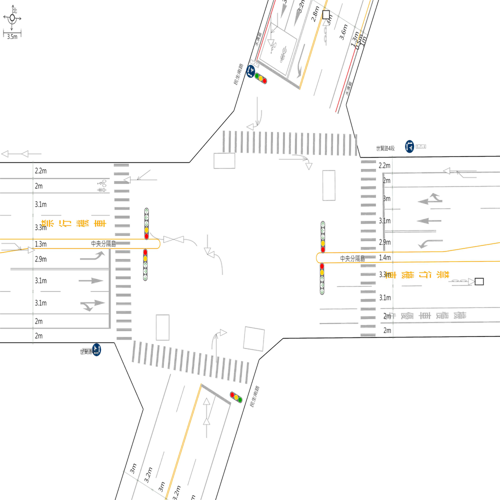

In [6]:
import random 
from PIL import Image


test_ds = ds['test']
sample = random.choice(test_ds)
print(sample['text'])
img = Image.open(sample['image'])
img = img.resize((500, 500))
img.show()

In [7]:
from utils.gen_utils import custom_system_prompt
from utils.gen_utils import json_schema, tools, safe_json_parse

# prompt = """你是一位專精台灣交通工程與交通安全的專家，請用繁體中文回答我的專業問題。請基於提供的肇事碰撞構圖，對路口進行分析並辨識肇事型態。
# 肇事型態有分為左轉側撞、右轉側撞、左轉穿越側撞、交叉撞、同向擦撞、追撞、匯入撞、對撞、其他(撞固定物、失控肇事)"""

prompt = "你是一位專精台灣交通工程與交通安全的專家，請用繁體中文回答我的專業問題。請基於提供的肇事碰撞構圖，對路口進行分析並辨識肇事型態。"

llm_gens = []
data_sources = []
for sample in tqdm(test_ds):
    image_data = encode_image(sample['image'])
    stream = client.chat.completions.create(
            model=client.models.list().data[0].id,
            messages= [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text":  prompt},
                    {"type": "image_url", "image_url": {"url": image_data}},
                ],
            },
            ],
            temperature=0.15,
            top_p=0.9,
            max_tokens=500,
            tools=tools,
            tool_choice="auto",
            stream=True
        )
    f = StringIO()
    for chunk in stream:
        if chunk.choices[0].delta.content is not None:
            f.write(chunk.choices[0].delta.content)
   
        print(chunk.choices[0].delta.content, end="")
    print()
    data_sources.append(sample['source'])
    llm_gens.append(f.getvalue())    

2026-09-22 13:40:26,612	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
  0%|          | 0/100 [00:00<?, ?it/s]

1.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
2.一方車由南往北方向直行，另一方車由東往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
3.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
4.一方車由南往北方向直行，另一方車由西往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
5.一方車由東往西方向直行，另一方車由南往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
6.一方車由北往南方向直行，另一方車由西往南方向右轉，兩車在南側路口遠端發生右轉匯入側撞
7.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在路段(

  1%|          | 1/100 [00:05<08:42,  5.28s/it]

往北)發生直行對撞
None
1.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
2.一方車由南往北方向直行，另一方車由東往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
3.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
4.一方車由東往西方向直行，另一方車由南往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
5.一方車由北往南方向直行，另一方車由西往南方向右轉，兩車在南側路口遠端發生右轉匯入側撞
6.一方車由南往北方向直行，另一方車由西往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
7.一方車由南往北方向直行，另一方車由北往南方向直行，兩車在路段(往

  2%|▏         | 2/100 [00:09<07:23,  4.53s/it]

...

 33%|███▎      | 33/100 [02:12<04:20,  3.89s/it]

往北)發生直行對撞
None
1.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
2.一方車由南往北方向直行，另一方車由東往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
3.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
4.一方車由南往北方向直行，另一方車由西往北方向右轉，兩車在北側路口遠端發生右轉匯入側撞
5.一方車由東往西方向直行，另一方車由南往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
6.一方車由北往南方向直行，另一方車由西往南方向右轉，兩車在南側路口遠端發生右轉匯入側撞
7.一方車由南往北方向直行，

 33%|███▎      | 33/100 [02:16<04:37,  4.14s/it]

另一方車由北往北方向右轉，

KeyboardInterrupt: 

In [ ]:
os.makedirs(inf_output_dir, exist_ok=True)

basename = os.path.basename(model.strip("/"))
filename = f"{basename}.jsonl"
texts = '\n'.join([json.dumps({"text":llm_gen}, ensure_ascii=False) for llm_gen in llm_gens])

with open(f"{inf_output_dir}/{filename}", 'w', encoding='utf-8') as f:
    f.write(texts)

print(texts)    

{"text": "1.兩方車皆由西往東方向直行，兩車在西側路段(往東)發生同向擦撞\n2.兩方車皆由東往西方向直行，兩車在東側路段(往西)發生同向擦撞\n3.一方車由西往東方向直行，另一方車由東往西方向行直行，兩車在西側鄰近路口發生直行對撞\n4.一方車由西往東方向直行，另一方車由東往西方向行直行，兩車在東側路段(往東)發生直行對撞\n5.一方車由西往東方向直行，另一方車由東往西方向行直行，兩車在西側路口近端發生右轉岔撞\n6.一方車由西往東方向直行，另一方車由東往西方向行直行，兩車在東側路口遠端發生左轉岔撞\n7.一方車由西往東方向倒車，兩車在西側路口遠端發生倒車自撞\n8.一方車由西往東方向倒車，兩車在東側路口近端發生倒車自撞\n9.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在南側路段(往北)發生直行對撞\n10.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在北側路段(往北)發生直行對撞\n11.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在南側鄰近路口發生直行對撞\n12.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在南側路口近端發生右轉岔"}
{"text": "1.兩方車皆由西往東方向直行，兩車在西側路段(往東)發生同向擦撞\n2.一方車由西往東方向直行，另一方車由東往西方向行直行，兩車在西側鄰近路口發生直行對撞\n3.一方車由西往東方向直行，另一方車由東往西方向行駛，兩車在西側路口近端發生右轉岔撞\n4.一方車由西往東方向直行，另一方車由東往西方向行駛，兩車在東側路口遠端發生右轉岔撞\n5.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在南側路段(往北)發生直行對撞\n6.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在北側路段(往北)發生直行對撞\n7.一方車由南往北方向直行，另一方車由北往南方向行直行，兩車在南側鄰近路口發生直行對撞\n8.一方車由南往北方向直行，另一方車由北往南方向行駛，兩車在南側路口近端發生左轉岔撞\n9.一方車由北往南方向直行，另一方車由南往北方向行直行，兩車在北側路段(往南)發生直行對撞\n10.一方車由北往南方向直行，另一方車由南往北方向行直行，兩車在北側鄰近路口發生直行對撞\n11.一方車由北往南方向直行，另一方車由北往南方向行駛，兩車在北側路口近端發

In [ ]:
from utils.report_utils import read_json_lines, parse_json_strings

data_list = read_json_lines(f'data/collision_diagram/{data_root}/test/test.jsonl')

In [ ]:
from utils.accuracy_utils import (
    extract_numbers,
    preprocess_text,
    calculate_char_accuracy,
    compare_texts_by_characters,
    extract_pointer,
    compare_extraction,
)

In [ ]:
# from utils.report_utils import create_excel_with_images_inf_data
from typing import Any
import openpyxl
from openpyxl.drawing.image import Image as OpenpyxlImage

def create_excel_with_images_inf_data(data_list, data_sources, llm_outputs, output_file='output.xlsx'):
    """
    建立包含圖片的 Excel 檔案

    參數:
        data_list: JSON 資料列表
        output_file: 輸出的 Excel 檔案名稱
    """
    # 建立工作簿和工作表
    wb = openpyxl.Workbook()
    ws = wb.active
    ws.title = "Inference Data"
    total_accuracy, qianmo_accuracy, transport_accuracy = [], [], []
    square_accuracy, skew_accuracy = [], []
    ocr_accuracy = []
    ocr_precision, ocr_recall, ocr_f1 = [], [], []

    # 設定標題列
    headers = ['Background', 'Image Path', 'Source', 'Text', 'Inference', 'Picture',
               'Text_Accuracy(%)', 'Icons_Accuracy(%)', 'OCR_Accuracy(%)',
               'OCR_Precision(%)', 'OCR_Recall(%)', 'OCR_F1(%)',
               'Compare', 'OCR_Report']
    ws.append(headers)

    # 設定標題列樣式
    for col in range(1, len(headers) + 1):
        cell = ws.cell(row=1, column=col)
        cell.font = openpyxl.styles.Font(bold=True)

    # 設定欄寬
    ws.column_dimensions['A'].width = 20
    ws.column_dimensions['B'].width = 37
    ws.column_dimensions['C'].width = 8
    ws.column_dimensions['D'].width = 80
    ws.column_dimensions['E'].width = 80
    ws.column_dimensions['F'].width = 80

    ws.column_dimensions['G'].width = 15
    ws.column_dimensions['H'].width = 15
    ws.column_dimensions['I'].width = 15
    ws.column_dimensions['J'].width = 15
    ws.column_dimensions['K'].width = 15
    ws.column_dimensions['L'].width = 15
    ws.column_dimensions['M'].width = 80
    ws.column_dimensions['N'].width = 80

    # 填入資料並插入圖片
    for idx, data in enumerate(data_list, start=2):
        # 填入文字資料
        background_cell = ws.cell(row=idx, column=1, value=data.get('background', ''))
        background_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')
        image_cell = ws.cell(row=idx, column=2, value=data.get('image', ''))
        image_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        # 填入 legend_source 欄位並設定自動換行
        legend_source = data_sources[idx-2]
        source_cell = ws.cell(row=idx, column=3, value=round(legend_source, 2) if isinstance(legend_source, float) else legend_source)
   
        source_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        # 填入 Text 欄位並設定自動換行
        text_cell = ws.cell(row=idx, column=4, value=data.get('text', ''))
        text_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        # 填入 llm_output 欄位並設定自動換行
        llm_output = llm_outputs[idx-2]
        llm_cell = ws.cell(row=idx, column=5, value=llm_output)
        llm_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        llm_answer = data.get('text', '')
        report_line, accuracy = compare_texts_by_characters(llm_answer, llm_output)

        # 填入 Text_Accuracy(%) 欄位並設定自動換行
        accuracy_cell = ws.cell(row=idx, column=7, value=round(accuracy, 2))   
        accuracy_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')
        # ---------------------------------------------------------------------------------------
        # 細指標比對
        icons_lbl = data.get('icons', '')
        ocr_nums_lbl = data.get('ocr_nums', '')
        ocr_labels_lbl = data.get('ocr_labels', '')
        lbl_result = {
            "icons_lbl": icons_lbl,
            "ocr_nums_lbl": ocr_nums_lbl,
            "ocr_labels_lbl": ocr_labels_lbl,
        }

        (icons, ocr_nums, ocr_labels) = extract_pointer(llm_output)
        # 結果輸出
        pred = {
            "icons": icons,
            "ocr_nums": ocr_nums,
            "ocr_labels": ocr_labels,
        }
        # 1️⃣ icon 準確率
        result, ocr_report = compare_extraction(lbl_result, pred, legend_source)

        # 填入 Icons_Accuracy(%) 欄位並設定自動換行
        icons_accuracy_cell = ws.cell(row=idx, column=8, value=round(result["icons_accuracy"], 2))
   
        icons_accuracy_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        # 填入 OCR_Accuracy(%) 欄位並設定自動換行
        ocr_accuracy_cell = ws.cell(row=idx, column=9, value=round(result["ocr_accuracy"], 2))
   
        ocr_accuracy_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        # 填入 OCR_Precision(%)/OCR_Recall(%)/OCR_F1(%) 欄位並設定自動換行
        ocr_precision_cell = ws.cell(row=idx, column=10, value=round(result["ocr_precision"], 2))
   
        ocr_precision_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')
        ocr_recall_cell = ws.cell(row=idx, column=11, value=round(result["ocr_recall"], 2))
        ocr_recall_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')
        ocr_f1_cell = ws.cell(row=idx, column=12, value=round(result["f1"], 2))
        ocr_f1_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')
   
        # ---------------------------------------------------------------------------------------
        # 填入 comp_cell 欄位並設定自動換行
        comp_cell = ws.cell(row=idx, column=13, value=report_line)
        comp_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        ocr_report_cell = ws.cell(row=idx, column=14, value=ocr_report)
        ocr_report_cell.alignment = openpyxl.styles.Alignment(wrap_text=True, vertical='top')

        total_accuracy.append(accuracy)
        if legend_source == "阡陌":
            ocr_accuracy.append(result["ocr_accuracy"])
            ocr_precision.append(result["ocr_precision"])
            ocr_recall.append(result["ocr_recall"])
        ocr_f1.append(result["f1"])
        if legend_source == "阡陌":
            qianmo_accuracy.append(accuracy)
        elif legend_source == "運研所":
            transport_accuracy.append(accuracy)

        road_type_lbl = data.get('road_type', '')
        if road_type_lbl == "正交":
            square_accuracy.append(accuracy)
        elif road_type_lbl == "斜交":
            skew_accuracy.append(accuracy)

        # 插入圖片
        image_path = data.get('image', '')
        if image_path and Path(image_path).exists():
            try:
                # 載入圖片
                img = OpenpyxlImage(image_path)

                # 調整圖片大小為 500x500
                img.width = 500
                img.height = 500

                # 設定列高以容納圖片
                ws.row_dimensions[idx].height = img.height * 0.75
                ws.row_dimensions[idx].width = img.width * 1.25

                # 將圖片錨定到 F 欄的儲存格
                cell_position = f'F{idx}'
                img.anchor = cell_position

                # 添加圖片到工作表
                ws.add_image(img)
            except Exception as e:
                ws.cell(row=idx, column=6, value=f'圖片載入失敗: {str(e)}')
                print(f"警告: 無法載入圖片 {image_path}: {str(e)}")
        else:
            ws.cell(row=idx, column=6, value='圖片不存在')
            print(f"警告: 找不到圖片檔案 {image_path}")

    # 在最後一列新增總體準確率
    if total_accuracy:
        avg_accuracy = sum(total_accuracy) / len(total_accuracy)
        print(type[Any](qianmo_accuracy))
        if type(qianmo_accuracy) == list:
            qianmo_accuracy = sum(qianmo_accuracy) / len(qianmo_accuracy)
        transport_accuracy = sum(transport_accuracy) / len(transport_accuracy)
        square_accuracy = sum(square_accuracy) / len(square_accuracy)
        skew_accuracy = sum(skew_accuracy) / len(skew_accuracy)
        ocr_accuracy = sum(ocr_accuracy) / len(ocr_accuracy)
        ocr_precision = sum(ocr_precision) / len(ocr_precision)
        ocr_recall = sum(ocr_recall) / len(ocr_recall)
        ocr_f1 = sum(ocr_f1) / len(ocr_f1)

        total_row = len(data_list) + 2
        ws.cell(row=total_row, column=7, value=f'Total accuracy: {avg_accuracy:.2f}%')
        if type(qianmo_accuracy) == list:
            ws.cell(row=total_row+1, column=7, value=f'阡陌 accuracy: {qianmo_accuracy:.2f}%')
        ws.cell(row=total_row+2, column=7, value=f'運研所 accuracy: {transport_accuracy:.2f}%')
        ws.cell(row=total_row+3, column=7, value=f'正交 accuracy: {square_accuracy:.2f}%')
        ws.cell(row=total_row+4, column=7, value=f'斜交 accuracy: {skew_accuracy:.2f}%')
        ws.cell(row=total_row+5, column=7, value=f'OCR accuracy: {ocr_accuracy:.2f}%')
        ws.cell(row=total_row+6, column=7, value=f'OCR precision: {ocr_precision:.2f}%')
        ws.cell(row=total_row+7, column=7, value=f'OCR recall: {ocr_recall:.2f}%')
        ws.cell(row=total_row+8, column=7, value=f'OCR F1: {ocr_f1:.2f}%')
        for i in range(9):
            ws.cell(row=total_row + i, column=7).font = openpyxl.styles.Font(bold=True)

    # 儲存檔案
    wb.save(output_file)
    print(f"Excel 檔案已成功建立: {output_file}")
    print(f"Total accuracy: {avg_accuracy :.2f}%")
    if type(qianmo_accuracy) == list:
        print(f"阡陌 accuracy: {qianmo_accuracy :.2f}%")
    print(f"運研所 accuracy: {transport_accuracy :.2f}%")
    print(f"正交 accuracy: {square_accuracy :.2f}%")
    print(f"斜交 accuracy: {skew_accuracy :.2f}%")
    print(f"OCR accuracy: {ocr_accuracy :.2f}%")
    print(f"OCR precision: {ocr_precision :.2f}%")
    print(f"OCR recall: {ocr_recall :.2f}%")
    print(f"OCR F1: {ocr_f1 :.2f}%")


In [ ]:
os.makedirs(inf_output_dir, exist_ok=True)
# 建立 Excel 檔案
create_excel_with_images_inf_data(data_list, data_sources, llm_gens,
    output_file=f'{inf_output_dir}/{basename}.xlsx')

# Total accuracy: 98.59%
# 阡陌 accuracy: 97.49%
# 運研所 accuracy: 99.56%
# 正交 accuracy: 98.50%
# 斜交 accuracy: 99.24%
# OCR accuracy: 96.66%

<class 'list'>
Excel 檔案已成功建立: Output/Ministral-3-8B-Instruct-2512-lora-run1/merged/Inference/merged.xlsx
Total accuracy: 45.76%
運研所 accuracy: 50.17%
正交 accuracy: 46.20%
斜交 accuracy: 45.28%
OCR accuracy: 0.00%
OCR precision: 0.00%
OCR recall: 0.00%
OCR F1: 0.00%
